# 23 - Séries de humidade do solo, escoamento e caudal

| | |
|---|---|
| **Tarefa do plano** | S2-06 - ERA5-Land (2006–2026), SMAP (2015–2026) e GloFAS (2006–2026) |
| **O que faz** | Resume as grelhas diárias em séries diárias e mensais para a bacia e para o distrito |
| **Usa** | ERA5-Land e SMAP (notebook 08), GloFAS (notebook 09) |
| **Produz** | `data/processed/series/hydromet_daily.csv` e `hydromet_monthly.csv` |

**Ideia simples.** A mesma chuva causa mais cheia quando o solo já está saturado e
o rio já vai cheio. Estas séries medem essas condições:

| Coluna | O que é | Fonte |
|---|---|---|
| `sm_era5_l1`, `sm_era5_l2` | água no solo, camadas 0–7 cm e 7–28 cm | ERA5-Land |
| `smap_surface`, `smap_rootzone` | humidade do solo medida por satélite | SMAP L4 |
| `runoff_mm` | água que escorre à superfície | ERA5-Land |
| `evap_mm`, `temp_c` | evaporação e temperatura | ERA5-Land |
| `discharge_m3s`, `q_mean`, `q_max`, `q_pct` | caudal do Incomáti em Marracuene | GloFAS |

Cada variável do ERA5-Land e do SMAP tem duas colunas: `_basin` e `_district`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
daily, monthly = drivers.build_hydromet_tables(cfg)
lat, lon = monthly.attrs["glofas_cell"]
print("diário :", daily.shape, "| mensal :", monthly.shape)
print(f"célula GloFAS usada para o caudal em Marracuene: lat {lat:.3f}, lon {lon:.3f}")

cobertura = pd.DataFrame({"primeiro": daily.apply(lambda s: s.first_valid_index()), "ultimo": daily.apply(lambda s: s.last_valid_index()),
                          "dias": daily.count()})
cobertura

diário : (7584, 16) | mensal : (250, 18)
célula GloFAS usada para o caudal em Marracuene: lat -25.725, lon 32.675


,primeiro,ultimo,dias
sm_era5_l1_basin,2006-01-01,2026-09-30,7578
sm_era5_l1_district,2006-01-01,2026-09-30,7578
sm_era5_l2_basin,2006-01-01,2026-09-30,7578
sm_era5_l2_district,2006-01-01,2026-09-30,7578
runoff_mm_basin,2006-01-01,2026-09-30,7578
runoff_mm_district,2006-01-01,2026-09-30,7578
evap_mm_basin,2006-01-01,2026-09-30,7578
evap_mm_district,2006-01-01,2026-09-30,7578
temp_c_basin,2006-01-01,2026-09-30,7578
temp_c_district,2006-01-01,2026-09-30,7578


## 1. As séries na bacia

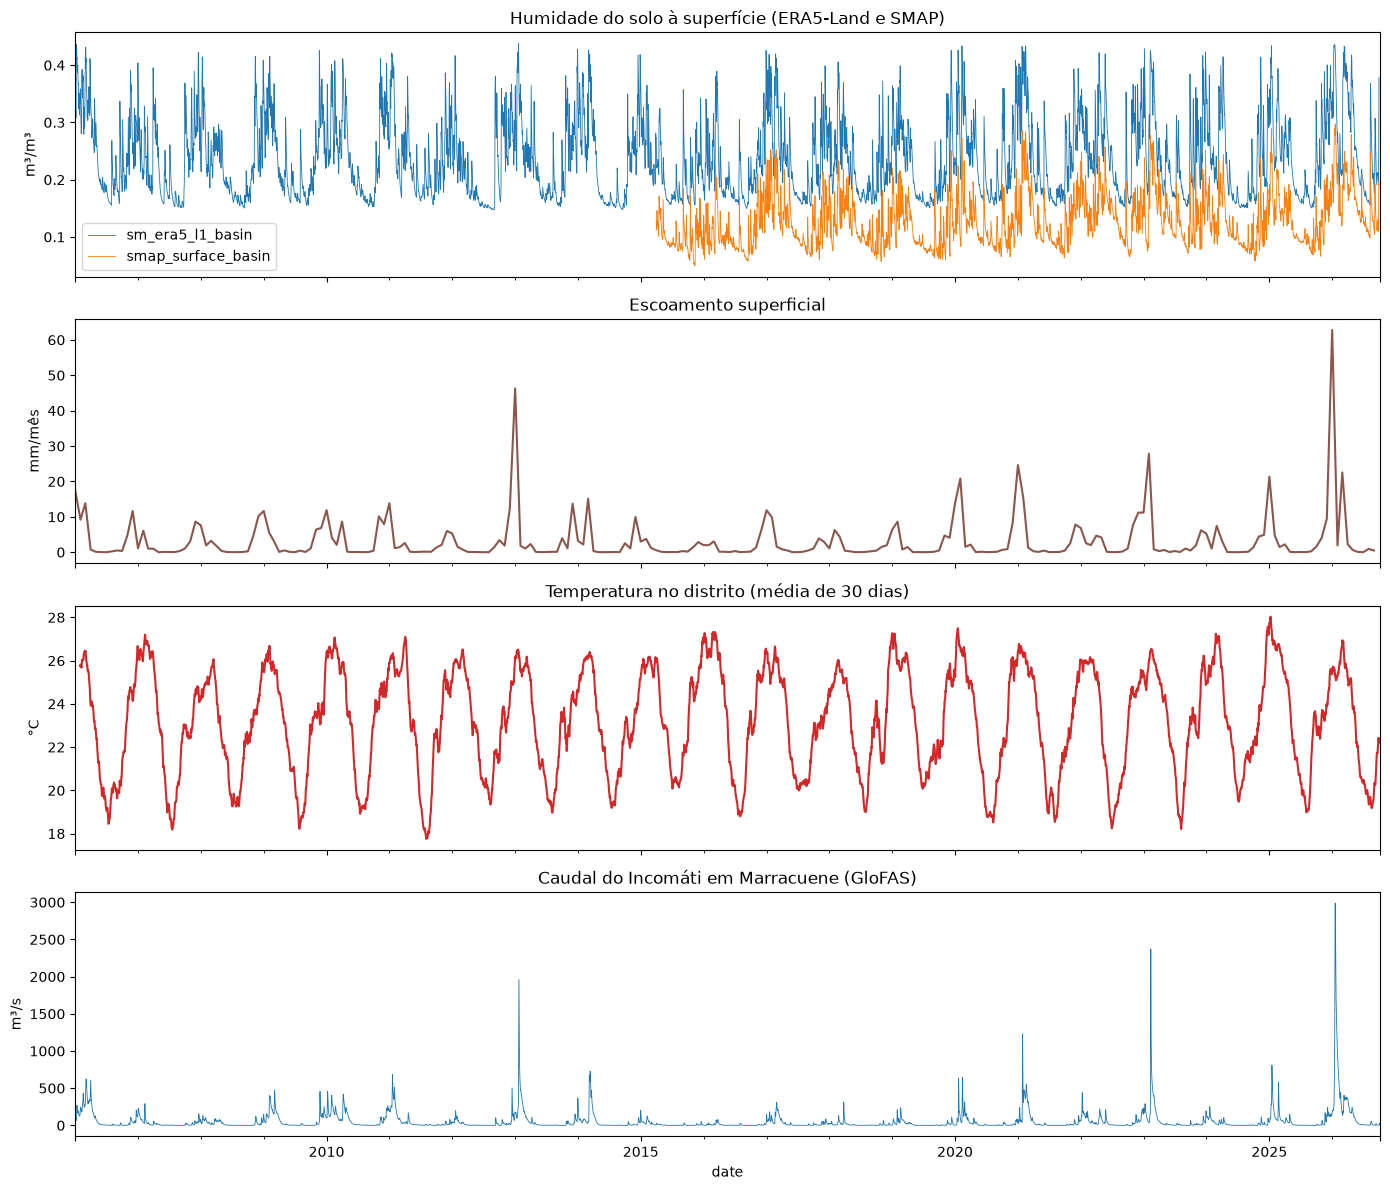

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
daily[["sm_era5_l1_basin", "smap_surface_basin"]].plot(ax=axes[0], linewidth=0.6); axes[0].set_ylabel("m³/m³"); axes[0].set_title("Humidade do solo à superfície (ERA5-Land e SMAP)")
monthly_dt = monthly.set_axis(pd.to_datetime(monthly.index))
monthly_dt["runoff_mm_basin"].plot(ax=axes[1], color="tab:brown"); axes[1].set_ylabel("mm/mês"); axes[1].set_title("Escoamento superficial")
daily["temp_c_district"].rolling(30).mean().plot(ax=axes[2], color="tab:red"); axes[2].set_ylabel("°C"); axes[2].set_title("Temperatura no distrito (média de 30 dias)")
daily["discharge_m3s"].plot(ax=axes[3], color="tab:blue", linewidth=0.6); axes[3].set_ylabel("m³/s"); axes[3].set_title("Caudal do Incomáti em Marracuene (GloFAS)")
plt.tight_layout(); plt.savefig(REPORTS / "23_series_hidromet.png", dpi=110)

## 2. Maiores caudais mensais

In [4]:
top = monthly.nlargest(10, "q_max")[["q_mean", "q_max", "q_pct", "q_provisional"]].round(1)
top.to_csv(REPORTS / "23_maiores_caudais.csv")
top

,q_mean,q_max,q_pct,q_provisional
month,,,,
2026-01,"1,117.800","2,986.900",100.000,0.000
2023-02,573.300,"2,370.700",100.000,0.000
2013-01,474.100,"1,961.500",95.200,0.000
2021-01,204.300,"1,229.700",76.200,0.000
2026-02,482.200,966.900,95.200,0.000
2025-01,278.000,808.900,85.700,0.000
2014-03,371.500,727.800,95.200,0.000
2011-01,340.800,684.200,90.500,0.000
2020-02,194.600,645.800,66.700,0.000


**Limites a ter em conta**

- O GloFAS é um **modelo** hidrológico global, não uma medição no rio. Serve para
  comparar meses e anos entre si; os valores absolutos podem diferir do caudal
  real, sobretudo num rio com barragens a montante como o Incomáti. Se a equipa
  conseguir dados de uma estação (ARA-Sul), devem ser usados para o verificar.
- `q_provisional = 1` marca meses do produto intermédio, que ainda vai ser revisto.
- ERA5-Land e SMAP têm células de cerca de 9–10 km: o distrito inteiro cabe em
  poucas células. Descrevem o estado geral do solo, não diferenças entre bairros.